<a href="https://colab.research.google.com/github/bayuaripermana/bayuaripermana/blob/main/destinasi_wisata_Bali.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

df =pd.read_csv("/content/bali_destinations_20260721_121044.csv")
print(df.shape)
print(df.dtypes)
print(df.isna().mean().round(2))

(1303, 12)
place_id                    object
place_name                  object
category                    object
location_region             object
coordinates_lat            float64
coordinates_lng            float64
price_min                  float64
price_max                  float64
contact_wa                 float64
ig_url                     float64
tiktok_url                 float64
visual_assets_indicator       bool
dtype: object
place_id                   0.00
place_name                 0.00
category                   0.00
location_region            0.00
coordinates_lat            0.00
coordinates_lng            0.00
price_min                  0.32
price_max                  0.32
contact_wa                 0.34
ig_url                     1.00
tiktok_url                 1.00
visual_assets_indicator    0.00
dtype: float64


In [7]:
df = pd.read_csv("bali_destinations_20260721_121044.csv")  # selalu mulai dari data mentah

df = df.drop(columns=["ig_url", "tiktok_url", "visual_assets_indicator", "price_max"],
             errors="ignore")
df = df.rename(columns={"price_min": "price"})

df["contact_wa"] = df["contact_wa"].astype("Int64").astype("string")
df["place_name"] = df["place_name"].str.strip().str.title()
df["region"] = df["location_region"].str.replace(" Bali", "", regex=False)

df = df.drop_duplicates(subset=["place_name", "coordinates_lat", "coordinates_lng"])

In [8]:
print("Nomor WA bukan 12-14 digit:",
      (~df["contact_wa"].str.fullmatch(r"\d{12,14}").fillna(True)).sum())
print(df.groupby("category")["price"].describe())

Nomor WA bukan 12-14 digit: 16
             count           mean           std      min        25%       50%  \
category                                                                        
Akomodasi    228.0  455522.877193  6.985911e+05  68406.0  201211.75  288940.0   
Alam          80.0  847369.550000  1.192179e+06     25.0  295235.50  560562.5   
Budaya        39.0  631489.384615  5.251957e+05     25.0  185000.00  500000.0   
Coffee Shop  199.0    2996.798995  2.575787e+04      1.0      25.00      25.0   
Kuliner      221.0   56172.113122  3.443172e+05      1.0      25.00      25.0   

                   75%        max  
category                           
Akomodasi    400820.50  6500000.0  
Alam         908620.25  8920073.0  
Budaya       913933.50  1992857.0  
Coffee Shop      50.00   250000.0  
Kuliner          50.00  4313722.0  


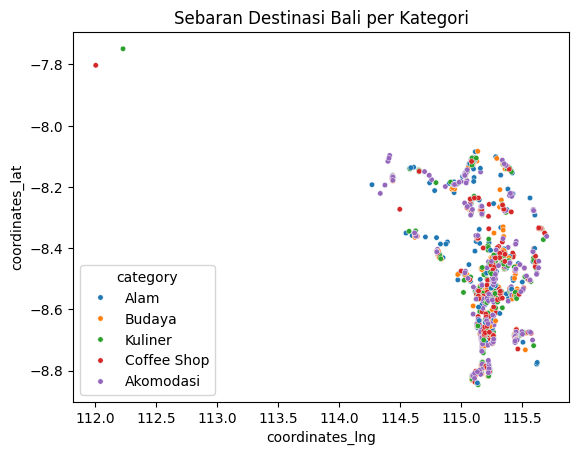

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df, x="coordinates_lng", y="coordinates_lat", hue="category", s=15)
plt.title("Sebaran Destinasi Bali per Kategori")
plt.show()

In [10]:
print(df.columns.tolist())

['place_id', 'place_name', 'category', 'location_region', 'coordinates_lat', 'coordinates_lng', 'price', 'contact_wa', 'region']


In [11]:
import numpy as np

df["outside_bali"] = ~(df["coordinates_lng"].between(114.4, 115.75)
                       & df["coordinates_lat"].between(-8.9, -8.0))

df["wa_valid"] = df["contact_wa"].str.fullmatch(r"\d{12,14}").fillna(False)

df["price_unit_check"] = np.where(
    df["price"].isna(), "Kosong",
    np.where(df["price"] < 1000, "Perlu verifikasi", "Rupiah")
)

In [12]:
ringkasan = (
    df.groupby("category")
    .agg(
        jumlah=("place_id", "count"),
        pct_ada_wa=("contact_wa", lambda s: round(s.notna().mean() * 100, 1)),
        pct_ada_harga=("price", lambda s: round(s.notna().mean() * 100, 1)),
    )
)
print(ringkasan)

             jumlah  pct_ada_wa  pct_ada_harga
category                                      
Akomodasi       236        70.8           96.6
Alam            211        58.3           37.9
Budaya          207        40.6           18.8
Coffee Shop     221        77.8           90.0
Kuliner         246        79.7           89.8


In [13]:
akomodasi = df[(df["category"] == "Akomodasi") & df["price"].notna()]
print(akomodasi["price"].agg(["count", "mean", "median", "max"]))

count     2.280000e+02
mean      4.555229e+05
median    2.889400e+05
max       6.500000e+06
Name: price, dtype: float64


In [14]:
(akomodasi.groupby("region")["price"]
    .agg(jumlah="count", median="median")
    .query("jumlah >= 5")
    .sort_values("median", ascending=False)
    .head(5))

,jumlah,median
region,,
Nusa Dua,5,1223637.0
Nusa Ceningan,5,544500.0
Petang,5,488033.0
Gerokgak,5,449839.0
Bangli,5,359400.0


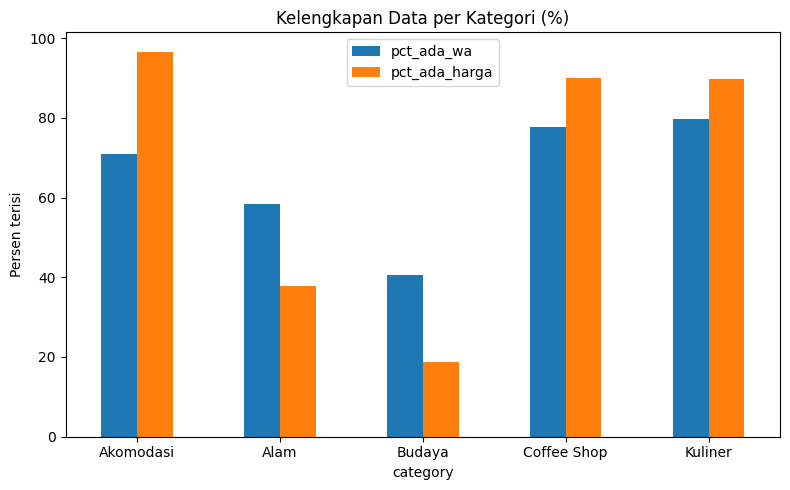

In [15]:
import matplotlib.pyplot as plt

ringkasan[["pct_ada_wa", "pct_ada_harga"]].plot(kind="bar", figsize=(8, 5))
plt.title("Kelengkapan Data per Kategori (%)")
plt.ylabel("Persen terisi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
df.to_csv("bali_clean.csv", index=False, encoding="utf-8-sig")
ringkasan.to_csv("bali_ringkasan_kategori.csv", encoding="utf-8-sig")

In [18]:
import os

df.to_csv("bali_clean.csv", index=False, encoding="utf-8-sig")
print("Folder kerja:", os.getcwd())
print("File ada?   :", os.path.exists("bali_clean.csv"))
print("Ukuran      :", os.path.getsize("bali_clean.csv"), "bytes")

Folder kerja: /content
File ada?   : True
Ukuran      : 168826 bytes


In [19]:
from google.colab import files
files.download("bali_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>